# CS 3110/5110: Data Privacy
## In-Class Exercise, week of 11/16/2026

In [ ]:
# Load the data and libraries
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt

def laplace_mech(v, sensitivity, epsilon):
    return v + np.random.laplace(loc=0, scale=sensitivity / epsilon)

def gaussian_mech(v, sensitivity, epsilon, delta):
    return v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)

def gaussian_mech_vec(vec, sensitivity, epsilon, delta):
    return [v + np.random.normal(loc=0, scale=sensitivity * np.sqrt(2*np.log(1.25/delta)) / epsilon)
            for v in vec]

def pct_error(orig, priv):
    return np.abs(orig - priv)/orig * 100.0

adult = pd.read_csv('https://github.com/jnear/cs3110-data-privacy/raw/main/homework/adult_with_pii.csv')

## Question 1

Implement `age_hist`, which returns a differentially private histogram of ages for ages 0-100 in the `adult` dataset.

Age
36    896.470874
31    888.357186
34    885.566304
23    876.909936
35    875.620151
         ...    
83      5.508720
88      4.385947
85      0.565586
86     -0.181544
87     -0.830701
Name: count, Length: 73, dtype: float64

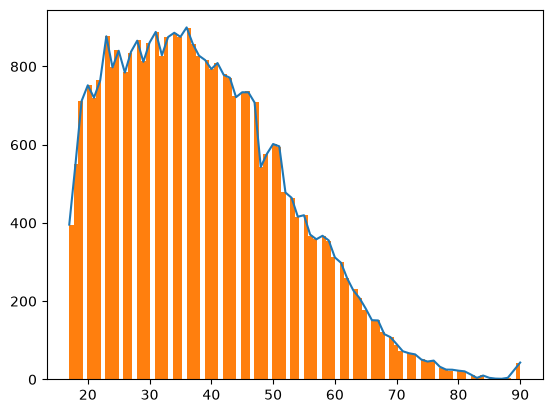

In [ ]:
def age_hist(epsilon):
    hist = adult['Age'].value_counts()
    noisy_hist = hist.apply(lambda x: laplace_mech(x, sensitivity=1, epsilon=epsilon))
    return noisy_hist

plt.plot(age_hist(1.0).sort_index());
plt.hist(adult['Age'], bins=100);
age_hist(1.0)

## Question 2

Using the *synthetic representation* of the differentially private histogram from question 1, answer the range query, "how many people are between the ages of 30 and 42?"

In [ ]:
def range_query_synth(syn_rep, a, b):
    total = 0
    for i in range(a, b):
        # Adds up noisy vals from hist
        total += syn_rep[i]
    return total

#Idea: Add up the counts of ages between 30 and 42
def between_30_42_syn(epsilon):
    # Entire epsilon to get noisy hist
    hist = age_hist(epsilon)
    # Uses no budget, post proc
    return range_query_synth(hist, 30, 42)
    
print('Synthetic answer:', between_30_42_syn(1.0))
print('True answer:', len(adult[(adult['Age'] >= 30) & (adult['Age'] < 42)]))

Synthetic answer: 10215.815131559591
True answer: 10215


## Question 3

Using the synthetic representation generated by the `age_hist` function, derive a differentially private approximation of the *one-way marginal* for the `Age` column of the `adult` dataset.

In [ ]:
def age_marginal(epsilon):
    hist = age_hist(epsilon)
    normalized = hist / hist.sum()
    return normalized.to_frame(name="probability").reset_index() #reset index: converts the index values into a regular data column.

marginal = age_marginal(1.0)

print('Sum of marginal probabilities:', np.sum(marginal['probability']))
marginal

Sum of marginal probabilities: 0.9999999999999999


,Age,probability
0,36,0.027582
1,31,0.027283
2,34,0.027186
3,23,0.026962
4,35,0.026934
...,...,...
68,83,0.000213
69,88,0.000090
70,85,0.000156
71,86,0.000038


## Question 4

Using the marginal constructed by `age_marginal`, sample *synthetic ages* from the probability distribution it represents.

In [ ]:
def gen_samples(n, marginal):
    weights = marginal.sample(n=n, replace=True, weights="probability")
    weights = weights = marginal["probability"].clip(lower=0)
    return weights

marginal = age_marginal(1.0)
syn_data = pd.DataFrame(gen_samples(5, marginal), columns=['Age'])
syn_data

,Age


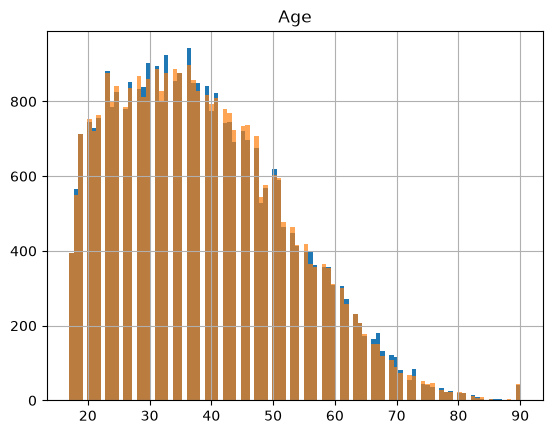

In [ ]:
syn_data = pd.DataFrame(gen_samples(len(adult), marginal), columns=['Age'])
syn_data.hist(bins=100)
adult['Age'].hist(alpha=0.7, bins = 100);

## Accuracy of Synthetic Representation

In [ ]:
epsilon = 1.0
syn_rep = age_hist(epsilon)

# Query 1: count with 40 <= age < 43
true_answer = len(adult[(adult['Age'] >= 40) & (adult['Age'] < 43)])
print('Q1 percent error, synthetic representation:', 
      pct_error(true_answer, range_query_synth(syn_rep, 40, 43)))

lap_answer = laplace_mech(true_answer, 1, epsilon)
print('Q1 percent error, Laplace mechanism:', 
      pct_error(true_answer, lap_answer))

Q1 percent error, synthetic representation: 0.01302411081332002
Q1 percent error, Laplace mechanism: 0.09212244884095333


In [ ]:
# Query 2: count with 25 <= age < 53
true_answer = len(adult[(adult['Age'] >= 25) & (adult['Age'] < 53)])
print('Q2 percent error, synthetic representation:', 
      pct_error(true_answer, range_query_synth(syn_rep, 25, 53)))

lap_answer = laplace_mech(true_answer, 1, epsilon)
print('Q2 percent error, Laplace mechanism:', 
      pct_error(true_answer, lap_answer))

Q2 percent error, synthetic representation: 0.006747280573622857
Q2 percent error, Laplace mechanism: 0.0087952263096741


## Question 5

Which approach gives more accurate answers: the Laplace mechanism or the synthetic representation? Under what conditions is the synthetic representation good, and under what conditions is it not as good?

The laplace is always at least a good as the syn rep
When range is small, syn rep is close to laplace mech
When range is big, syn rep has a lot more error than laplace mech [adding up many noisy samples]

## Question 6

Implement a synthetic representation for *two dimensions*: `Age` and `Occupation`.

In [ ]:
def age_occupation_hist(epsilon):
    hist = adult[["Age", "Occupation"]].value_counts()
    dp_hist = hist.apply(lambda x: laplace_mech(x, sensitivity=1, epsilon=epsilon))
    return dp_hist

age_occupation_hist(1.0)

Age  Occupation      
19   Other-service       163.971155
37   Craft-repair        154.372374
18   Other-service       153.272305
38   Exec-managerial     151.714584
     Craft-repair        145.857404
                            ...    
30   Priv-house-serv       0.416369
75   Transport-moving      0.549642
17   Exec-managerial       0.623954
90   Protective-serv      -0.846898
85   Exec-managerial       5.959333
Name: count, Length: 843, dtype: float64

## Question 7

Using the synthetic representation from Question 6, implement functions to calculate the *two-way marginal distribution* and generate synthetic data samples.

In [ ]:
def age_occupation_marginal(epsilon):
    syn_rep = age_occupation_hist(epsilon=epsilon)

    
    syn_rep = syn_rep.clip(lower=0) # I added this to fix ValueError: weight vector many not include negative values

    marginal = syn_rep / syn_rep.sum() #Normalization step, everything sums to 1
    return marginal.to_frame(name="probability").reset_index()

def gen_samples(n, marginal):
    samples = marginal.sample(n=n, replace=True, weights="probability")
    return samples[["Age", "Occupation"]]

marginal = age_occupation_marginal(1.0)
gen_samples(15, marginal)

,Age,Occupation
184,55,Exec-managerial
206,34,Machine-op-inspct
103,26,Sales
173,36,Other-service
307,22,Transport-moving
213,56,Craft-repair
280,47,Machine-op-inspct
330,54,Transport-moving
26,37,Exec-managerial
79,31,Other-service


In [ ]:
syn_data = gen_samples(len(adult), marginal)
syn_data["Age"].mean()

np.float64(38.434599674457175)

## Question 8

Generate synthetic data for the Age and Occupation columns by using a two-way marginal as a *conditional distribution*. Use `age_marginal` to generate data for the Age column, then use `age_occupation_marginal` to generate the Occupation column by *conditioning* on the Age column.

In [ ]:
def gen_age_occupation_conditional(n, epsilon):
    def gen_conditional(s, m, cond, target):
        return m[m[cond] == s].sample(n=1, weights='probability')[target].values[0]

    m1 = age_marginal(epsilon/2)
    m2 = age_occupation_marginal(epsilon/2)
    samples = m1.sample(n=n, replace=True, weights='probability')
    samples['Occupation'] = [gen_conditional(s, m2, 'Age', 'Occupation') for s in samples['Age']]
    return samples[['Age', 'Occupation']]

ValueError: weight vector many not include negative values